In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import re

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("")
df["body_text"] = df["body_text"].fillna("")

df["text"] = df["headline"] + " " + df["body_text"]

print("Dataset loaded successfully!")
print(df["label"].value_counts())

Dataset loaded successfully!
label
Fake    1110
Real    1102
Name: count, dtype: int64


In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_text"] = df["text"].apply(clean_text)

print(df[["label", "clean_text"]].head())

  label                                         clean_text
0  Real  global economy faces recession the prime minis...
1  Real  earthquake hits chittagong panic spreads gover...
2  Fake  breakthrough in bangladesh s tech industry loc...
3  Fake  dengue situation worsens in the country the pr...
4  Real  new virus outbreak sparks fear government sour...


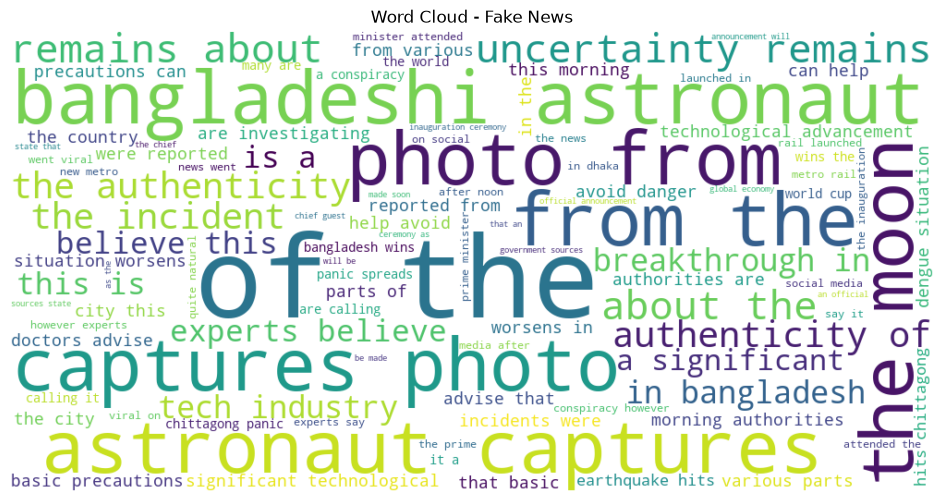

In [5]:
fake_text = " ".join(
    df.loc[df["label"].str.lower() == "fake", "clean_text"]
)

fake_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords="english",
    max_words=100
).generate(fake_text)

plt.figure(figsize=(12, 6))
plt.imshow(fake_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Fake News")
plt.show()

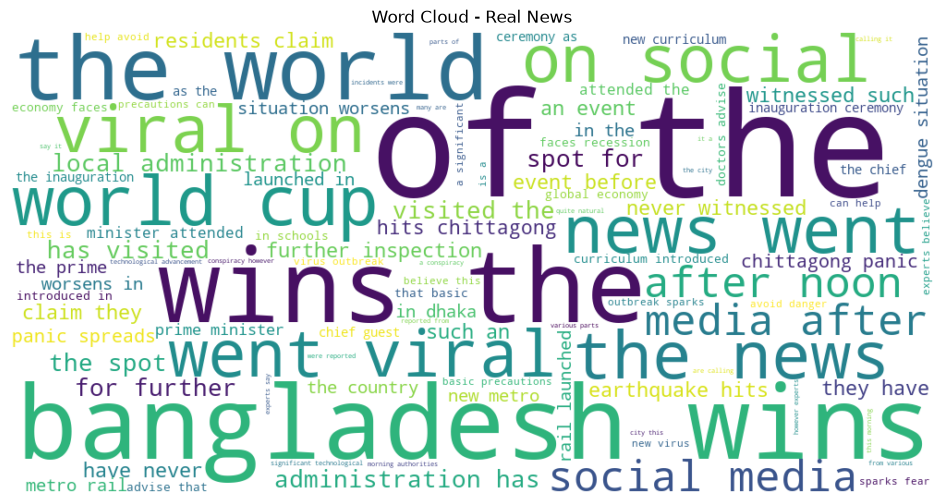

In [6]:
real_text = " ".join(
    df.loc[df["label"].str.lower() == "real", "clean_text"]
)

real_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords="english",
    max_words=100
).generate(real_text)

plt.figure(figsize=(12, 6))
plt.imshow(real_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Real News")
plt.show()

In [7]:
fake_wordcloud.to_file("T28_fake_news_wordcloud.png")
real_wordcloud.to_file("T28_real_news_wordcloud.png")

print("Word clouds saved successfully!")

Word clouds saved successfully!
